## Predicting U.S. House Vote Share from Campaign Finance and Race Characteristics

**Question:** How much of a candidate's 2024 U.S. House vote share can be explained by their fundraising compared with their opponents', together with party, incumbency and state?

**Target:** vote share = candidate's votes ÷ all valid votes in the district
- The predicted winner is the candidate with the highest predicted share in each district

**Data sources**
- FEC Candidate Summary, 2023–2024 cycle: `candidate_summary_2024.csv`
- MIT Election Data and Science Lab, *U.S. House 1976–2024* (v15.0), https://doi.org/10.7910/DVN/IG0UN2: `1976-2024-house.tab`
- FEC "All candidates" file, 2023–2024 (`weball24.txt`): checked as a backup source for missing candidates, but not used

Janna Hoyne ANA 680

In [1]:
import json                # save defaults.json for the app
import os                  # create the Figures and Models folders
import re                  # clean candidate names (regular expressions)
import unicodedata         # strip accents from names

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# splitting and cross-validation
from sklearn.model_selection import (GroupShuffleSplit, GroupKFold,
                                     cross_validate, cross_val_predict)

# preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# evaluation
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

In [2]:
fec = pd.read_csv("../Data/candidate_summary_2024.csv")
mit = pd.read_csv("../Data/1976-2024-house.tab") 

print("FEC:", fec.shape)
print("MIT:", mit.shape)

FEC: (5302, 50)
MIT: (33805, 20)


C:\Users\Janna Hoyne\AppData\Local\Temp\ipykernel_40108\1040773189.py:2: DtypeWarning: Columns (9: runoff) have mixed types. Specify dtype option on import or set low_memory=False.
  mit = pd.read_csv("../Data/1976-2024-house.tab")


In [3]:
mit = pd.read_csv("../Data/1976-2024-house.tab", low_memory=False)

In [4]:
fec.head()

,Link_Image,Cand_Name,Cand_Id,Cand_Office,Cand_Office_St,Cand_Office_Dist,Cand_Party_Affiliation,Cand_Incumbent_Challenger_Open_Seat,Total_Receipt,Total_Disbursement,Cash_On_Hand_COP,Debt_Owed_By_Committee,Coverage_End_Date,Cand_Street_1,Cand_Street_2,Cand_City,Cand_State,Cand_Zip,Individual_Itemized_Contribution,Individual_Unitemized_Contribution,Individual_Contribution,Other_Committee_Contribution,Party_Committee_Contribution,Cand_Contribution,Total_Contribution,Transfer_From_Other_Auth_Committee,Cand_Loan,Other_Loan,Total_Loan,Offsets_To_Operating_Expenditure,Offsets_To_Fundraising,Offsets_To_Leagal_Accounting,Other_Receipts,Operating_Expenditure,Exempt_Legal_Accounting_Disbursement,Fundraising_Disbursement,Transfer_To_Other_Auth_Committee,Cand_Loan_Repayment,Other_Loan_Repayment,Total_Loan_Repayment,Individual_Refund,Party_Committee_Refund,Other_Committee_Refund,Total_Contribution_Refund,Other_Disbursements,Net_Contribution,Net_Operating_Expenditure,Cash_On_Hand_BOP,Debt_Owe_To_Committee,Coverage_Start_Date
0,https://www.fec.gov/data/candidate/H0AL01055/?...,"CARL, JERRY LEE, JR",H0AL01055,H,AL,1.0,REP,INCUMBENT,2246839.19,2631446.59,69290.42,254535.87,12/31/2024,PO BOX 852138,NaN,MOBILE,AL,36685,757652.83,305386.55,1063039.38,634500.00,0.0,0.0,1697539.38,547807.76,0.00,0.0,0.00,1492.04,0.0,0.0,0.01,2149928.29,0,0.0,27316.59,176202.71,0.0,176202.71,193499.0,0.0,84500.0,277999.0,0.0,1419540.38,2148436.25,453897.82,0.0,01/01/2023
1,https://www.fec.gov/data/candidate/H0AL01097/?...,"AVERHART, JAMES",H0AL01097,H,AL,2.0,DEM,CHALLENGER,8876.56,6240.74,2757.53,34403.22,12/31/2024,811 SPRINGHILL AV,NaN,MOBILE,AL,36602,2750.00,968.34,3718.34,0.00,0.0,0.0,3718.34,0.00,5158.22,0.0,5158.22,0.00,0.0,0.0,0.00,6240.74,0,0.0,0.00,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,3718.34,6240.74,121.71,0.0,01/01/2023
2,https://www.fec.gov/data/candidate/H0AL02202/?...,"HARVEY-HALL, PHYLLIS",H0AL02202,H,AL,2.0,DEM,CHALLENGER,16284.00,5610.17,10894.41,6405.00,02/21/2024,P.O. BOX 11564,NaN,MONTGOMERY,AL,36111,6104.00,175.00,6279.00,0.00,0.0,4800.0,11079.00,0.00,5205.00,0.0,5205.00,0.00,0.0,0.0,0.00,5610.17,0,0.0,0.00,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,11079.00,5610.17,220.58,0.0,01/01/2023
3,https://www.fec.gov/data/candidate/H0AL07086/?...,"SEWELL, TERRI A.",H0AL07086,H,AL,7.0,DEM,INCUMBENT,3036770.95,2462142.12,3470560.90,0.00,12/31/2024,PO BOX 1964,NaN,BIRMINGHAM,AL,35201,894692.69,78204.30,972896.99,2063873.95,0.0,0.0,3036770.94,0.00,0.00,0.0,0.00,0.01,0.0,0.0,0.00,2231302.12,0,0.0,0.00,0.00,0.0,0.00,10412.0,0.0,0.0,10412.0,220428.0,3026358.94,2231302.11,2895932.07,0.0,01/01/2023
4,https://www.fec.gov/data/candidate/H0AR01083/?...,"CRAWFORD, ERIC ALAN RICK",H0AR01083,H,AR,1.0,REP,INCUMBENT,1098029.43,889704.90,830826.86,0.00,12/31/2024,34 CR 455,NaN,JONESBORO,AR,72404,315335.00,10022.92,325357.92,740193.96,1750.0,0.0,1067301.88,7749.97,0.00,0.0,0.00,0.00,0.0,0.0,22977.58,553618.90,0,0.0,205086.00,0.00,0.0,0.00,0.0,0.0,1000.0,1000.0,130000.0,1066301.88,553618.90,622502.33,0.0,01/01/2023


In [5]:
mit.head()

,year,state,state_po,state_fips,state_cen,state_ic,office,district,stage,runoff,special,candidate,party,writein,mode,candidatevotes,totalvotes,unofficial,version,fusion_ticket
0,1976,ALABAMA,AL,1,63,41,US HOUSE,1,GEN,False,False,BILL DAVENPORT,DEMOCRAT,False,TOTAL,58906,157170,False,20250910,False
1,1976,ALABAMA,AL,1,63,41,US HOUSE,1,GEN,False,False,JACK EDWARDS,REPUBLICAN,False,TOTAL,98257,157170,False,20250910,False
2,1976,ALABAMA,AL,1,63,41,US HOUSE,1,GEN,False,False,WRITEIN,NaN,True,TOTAL,7,157170,False,20250910,False
3,1976,ALABAMA,AL,1,63,41,US HOUSE,2,GEN,False,False,J CAROLE KEAHEY,DEMOCRAT,False,TOTAL,66288,156362,False,20250910,False
4,1976,ALABAMA,AL,1,63,41,US HOUSE,2,GEN,False,False,"WILLIAM L \""BILL\"" DICKINSON",REPUBLICAN,False,TOTAL,90069,156362,False,20250910,False


In [6]:
# Clean FEC: keep House candidates who ran a real campaign
keep_cols = [
    "Cand_Name", "Cand_Id", "Cand_Office", "Cand_Office_St", "Cand_Office_Dist",
    "Cand_Party_Affiliation", "Cand_Incumbent_Challenger_Open_Seat",
    "Total_Receipt", "Total_Disbursement", "Cash_On_Hand_BOP", "Cash_On_Hand_COP",
    "Debt_Owed_By_Committee",
    "Individual_Unitemized_Contribution",   # small donors (under $200)
    "Individual_Contribution",
    "Other_Committee_Contribution",         # PACs
    "Party_Committee_Contribution",
    "Cand_Contribution", "Cand_Loan",       # self-funding
]
fec_h = fec[keep_cols].copy()
print("All FEC candidates:", len(fec_h))

fec_h = fec_h[fec_h["Cand_Office"] == "H"]
print("House only:", len(fec_h))

fec_h = fec_h[fec_h["Total_Receipt"] >= 5000]
print("Raised $5,000 or more:", len(fec_h))

# District: 1.0 to 1
fec_h["Cand_Office_Dist"] = fec_h["Cand_Office_Dist"].astype("Int64")
fec_h.head()

All FEC candidates: 5302
House only: 3078
Raised $5,000 or more: 1722


,Cand_Name,Cand_Id,Cand_Office,Cand_Office_St,Cand_Office_Dist,Cand_Party_Affiliation,Cand_Incumbent_Challenger_Open_Seat,Total_Receipt,Total_Disbursement,Cash_On_Hand_BOP,Cash_On_Hand_COP,Debt_Owed_By_Committee,Individual_Unitemized_Contribution,Individual_Contribution,Other_Committee_Contribution,Party_Committee_Contribution,Cand_Contribution,Cand_Loan
0,"CARL, JERRY LEE, JR",H0AL01055,H,AL,1,REP,INCUMBENT,2246839.19,2631446.59,453897.82,69290.42,254535.87,305386.55,1063039.38,634500.00,0.0,0.0,0.00
1,"AVERHART, JAMES",H0AL01097,H,AL,2,DEM,CHALLENGER,8876.56,6240.74,121.71,2757.53,34403.22,968.34,3718.34,0.00,0.0,0.0,5158.22
2,"HARVEY-HALL, PHYLLIS",H0AL02202,H,AL,2,DEM,CHALLENGER,16284.00,5610.17,220.58,10894.41,6405.00,175.00,6279.00,0.00,0.0,4800.0,5205.00
3,"SEWELL, TERRI A.",H0AL07086,H,AL,7,DEM,INCUMBENT,3036770.95,2462142.12,2895932.07,3470560.90,0.00,78204.30,972896.99,2063873.95,0.0,0.0,0.00
4,"CRAWFORD, ERIC ALAN RICK",H0AR01083,H,AR,1,REP,INCUMBENT,1098029.43,889704.90,622502.33,830826.86,0.00,10022.92,325357.92,740193.96,1750.0,0.0,0.00


**FEC cleaning**
- Started with 5,302 candidates in the FEC file
- Kept only House candidates: 3,078
- Kept candidates who raised $5,000 or more: 1,722
    - the FEC requires candidates to register once they pass $5,000, so those below it usually never ran a real campaign

For matching to the election results, all 3,078 House filers were used, so minor candidates who raised less than $5,000 still kept their real (small) fundraising totals.

In [7]:
# keep the 2024 general election
mit24 = mit[mit["year"] == 2024].copy()
print("2024 rows:", len(mit24))

mit24 = mit24[mit24["stage"] == "GEN"]
print("General election only:", len(mit24))

# special and runoff can be True/False/blank (treat only "TRUE" as true)
is_special = mit24["special"].astype(str).str.upper() == "TRUE"
is_runoff  = mit24["runoff"].astype(str).str.upper() == "TRUE"
mit24 = mit24[~is_special & ~is_runoff]
print("No specials or runoffs:", len(mit24))

print("\nWrite-in rows:", (mit24["writein"] == True).sum())
print("\nVote modes:\n", mit24["mode"].value_counts())
print("\nNames in capital letters with no space (often not real people):")
print(mit24.loc[~mit24["candidate"].str.contains(" ", na=False), "candidate"].value_counts())

2024 rows: 1353
General election only: 1353
No specials or runoffs: 1353

Write-in rows: 119

Vote modes:
 mode
TOTAL    1353
Name: count, dtype: int64

Names in capital letters with no space (often not real people):
candidate
WRITEIN          56
SCATTERING       34
BLANK            27
VOID             14
BLANKS            9
MISCELLANEOUS     6
INDEPENDENT       1
CONSERVATIVE      1
Name: count, dtype: int64


In [8]:
cols = ["state_po", "district", "candidate", "party", "candidatevotes", "totalvotes", "fusion_ticket"]
odd = mit24[mit24["candidate"].isin(["INDEPENDENT", "CONSERVATIVE"])]
print(odd[cols])

for _, r in odd.iterrows():
    print(f"\n{r.state_po}-{r.district}")
    print(mit24[(mit24.state_po == r.state_po) & (mit24.district == r.district)][cols])

check = mit24.groupby(["state_po", "district"]).agg(
    reported_total=("totalvotes", "first"),
    sum_of_rows=("candidatevotes", "sum"),
)
mismatch = check[check.reported_total != check.sum_of_rows]
print(f"\nDistricts where totalvotes != sum of rows: {len(mismatch)} of {len(check)}")
print(mismatch.head(10))

      state_po  district     candidate         party  candidatevotes  \
32666       CT         3   INDEPENDENT           NaN            5018   
33254       NY         5  CONSERVATIVE  COMMON SENSE            5840   

       totalvotes  fusion_ticket  
32666      328923          False  
33254      231736           True  

CT-3
      state_po  district         candidate       party  candidatevotes  \
32666       CT         3       INDEPENDENT         NaN            5018   
32667       CT         3    MICHAEL MASSEY  REPUBLICAN          130095   
32668       CT         3  OMAR SCOTT ANTAR         NaN               2   
32669       CT         3   ROSA L. DELAURO    DEMOCRAT          193684   
32670       CT         3        SHAHD OMAR         NaN             124   

       totalvotes  fusion_ticket  
32666      328923          False  
32667      328923          False  
32668      328923          False  
32669      328923          False  
32670      328923          False  

NY-5
      state

In [9]:
not_votes = ["BLANK", "BLANKS", "VOID", "BLANK VOTES", "UNDER VOTES", "UNDERVOTES",
             "OVER VOTES", "OVERVOTES", "EXHAUSTED BALLOTS"]          # not a valid vote for anyone
mit24 = mit24[~mit24["candidate"].isin(not_votes)].copy()
print("After removing blank/void rows:", len(mit24))

mit24["district_total"] = mit24.groupby(["state_po", "district"])["candidatevotes"].transform("sum")

not_people = ["WRITEIN", "SCATTERING", "MISCELLANEOUS", "INDEPENDENT", "CONSERVATIVE",
              "ALL OTHERS", "WORKING FAMILIES", "OTHER WRITE-INS"]   # valid votes, but not a person
mit24 = mit24[~mit24["candidate"].isin(not_people) & (mit24["writein"] != True)]
print("After removing write-ins and non-candidates:", len(mit24))

# remaining rows with no party
print("\nNo-party names left:")
print(mit24.loc[mit24["party"].isna(), ["state_po", "district", "candidate"]].to_string())

mit24 = mit24.sort_values("candidatevotes", ascending=False)
mit_c = mit24.groupby(["state_po", "district", "candidate"], as_index=False).agg(
    votes=("candidatevotes", "sum"),
    party=("party", "first"),
    district_total=("district_total", "first"),
)
print("After combining fusion-ticket rows:", len(mit_c))

mit_c["vote_share"] = mit_c["votes"] / mit_c["district_total"]

n_cands = mit_c.groupby(["state_po", "district"])["candidate"].transform("count")
uncontested = (n_cands < 2) | (mit_c["district_total"] <= 0)
print("Uncontested districts dropped:",
      mit_c.loc[uncontested, ["state_po", "district"]].drop_duplicates().shape[0])
mit_c = mit_c[~uncontested]

print("\nFinal:", len(mit_c), "candidates in",
      mit_c.groupby(["state_po", "district"]).ngroups, "districts")
mit_c.sort_values(["state_po", "district", "vote_share"], ascending=[True, True, False]).head(10)

After removing blank/void rows: 1284
After removing write-ins and non-candidates: 1104

No-party names left:
Empty DataFrame
Columns: [state_po, district, candidate]
Index: []
After combining fusion-ticket rows: 1069
Uncontested districts dropped: 22

Final: 1047 candidates in 414 districts


,state_po,district,candidate,votes,party,district_total,vote_share
3,AK,0,NICK BEGICH,159550,REPUBLICAN,329555,0.484138
2,AK,0,MARY SATTLER PELTOLA,152828,DEMOCRAT,329555,0.463740
1,AK,0,JOHN WAYNE HOWE,13010,INDEPENDENCE,329555,0.039477
0,AK,0,ERIC HAFNER,3417,DEMOCRAT,329555,0.010369
4,AL,1,BARRY MOORE,258619,REPUBLICAN,329854,0.784041
5,AL,1,TOM HOLMES,70929,DEMOCRAT,329854,0.215031
7,AL,2,SHOMARI FIGURES,158041,DEMOCRAT,289674,0.545582
6,AL,2,CAROLEENE DOBSON,131414,REPUBLICAN,289674,0.453662
12,AL,6,GARY J. PALMER,243741,REPUBLICAN,346625,0.703184
11,AL,6,ELIZABETH ANDERSON,102504,DEMOCRAT,346625,0.295720


**MIT cleaning (2024 general election)**
- Started with 1,353 rows for 2024
- Removed blank, void, under-vote, over-vote and exhausted ballots: 1,284
  - These are ballots that didn't count as a vote for anyone
- Removed write-ins and rows that weren't real candidates (like "SCATTERING" and "ALL OTHERS"): 1,104
- Combined fusion-ticket rows: 1,069
  - In states like New York, one candidate can appear on several party lines, so their votes were added together into one row
- Dropped 22 uncontested races: 1,047 candidates in 414 districts
  - A candidate running unopposed gets 100%, which says nothing about money

**Vote share = candidate's votes ÷ all valid votes in the district**
- I calculated this myself instead of using MIT's `totalvotes` column, because New York's totals leave out blank ballots and Florida reports -1 for unopposed races
- Alaska and Maine use ranked-choice voting, vote counts are used as MIT reports them (Maine's include an "exhausted ballots" row, which suggests final-round counts)

**First matching attempt** (kept to show the process)
- Matched the two files on district & last name
- 42 real candidates didn't match
- The "1043 of 1047 (100%)" match count is inflated
   - some candidates matched more than one FEC record, which gave 1,085 rows instead of 1,047
- The unmatched list showed why names weren't matching:
  - Accents: MIT has "VELáZQUEZ", FEC has "VELAZQUEZ"
  - Two-word last names: MIT's last word is "DUYNE", but FEC's last name is "VAN DUYNE"
  - Curly apostrophes: "D’ESPOSITO" vs. "D'ESPOSITO"
  - Suffixes: FEC puts "III" before the comma ("WHALEN III, JOHN")
- These patterns led to the improved matching below

In [10]:
#matching key
SUFFIXES = {"JR", "SR", "II", "III", "IV", "V"}

def fec_last(name):
    return name.split(",")[0].strip()

def mit_last(name):
    name = re.sub(r'\\?".*?\\?"', " ", name)   # remove "nicknames"
    name = re.sub(r"\(.*?\)", " ", name)        # remove (nicknames)
    words = [w.strip(".,") for w in name.split()]
    words = [w for w in words if w and w not in SUFFIXES]
    return words[-1]

# All House filers (no $5k cutoff), district as a whole number
fec_house = fec.loc[fec["Cand_Office"] == "H", keep_cols].copy()
fec_house["Cand_Office_Dist"] = fec_house["Cand_Office_Dist"].astype("Int64")

# States with a single at-large seat (numbered 0 in MIT)
at_large = ["AK", "DE", "ND", "SD", "VT", "WY"]

#FEC House candidates have no district number
no_dist = fec_house["Cand_Office_Dist"].isna()
print("House filers with no district:", no_dist.sum())
print(fec_house.loc[no_dist, "Cand_Office_St"].value_counts())

# In an at-large state, a blank district means the one seat
fec_house.loc[no_dist & fec_house["Cand_Office_St"].isin(at_large), "Cand_Office_Dist"] = 0

# Keys: district key + last name, in both files
fec_house["key"]  = fec_house["Cand_Office_St"] + "-" + fec_house["Cand_Office_Dist"].astype(str)
fec_house["last"] = fec_house["Cand_Name"].apply(fec_last)
mit_c["key"]  = mit_c["state_po"] + "-" + mit_c["district"].astype(str)
mit_c["last"] = mit_c["candidate"].apply(mit_last)

# Check that at-large states use the same district number in both files
print("\nFEC at-large keys:", sorted(fec_house.loc[fec_house.Cand_Office_St.isin(at_large), "key"].dropna().unique()))
print("MIT at-large keys:", sorted(mit_c.loc[mit_c.state_po.isin(at_large), "key"].unique()))

# Merge
merged = mit_c.merge(fec_house, on=["key", "last"], how="left", indicator=True)
print(f"\nMIT candidates: {len(mit_c)}   rows after merge: {len(merged)}")
print("(If rows after merge is bigger, some names matched more than one FEC record)")

matched = (merged["_merge"] == "both").sum()
print(f"Matched automatically: {matched} of {len(mit_c)} ({matched/len(mit_c):.0%})")

# not matched
unmatched = merged.loc[merged["_merge"] == "left_only", ["key", "candidate", "party", "vote_share"]]
print(f"\nUnmatched: {len(unmatched)}")
print(unmatched.sort_values("vote_share", ascending=False).head(30).to_string())

House filers with no district: 6
Cand_Office_St
MD    2
AK    1
DE    1
OR    1
TX    1
Name: count, dtype: int64

FEC at-large keys: ['AK-0', 'DE-0', 'ND-0', 'SD-0', 'VT-0', 'WY-0']
MIT at-large keys: ['AK-0', 'DE-0', 'ND-0', 'SD-0', 'VT-0', 'WY-0']

MIT candidates: 1047   rows after merge: 1085
(If rows after merge is bigger, some names matched more than one FEC record)
Matched automatically: 1043 of 1047 (100%)

Unmatched: 42
        key                 candidate       party  vote_share
441    MD-4                GLENN IVEY    DEMOCRAT    0.884216
709    NY-7        NYDIA M. VELáZQUEZ    DEMOCRAT    0.779131
130   CA-44     NANETTE DIAZ BARRAGáN    DEMOCRAT    0.713726
322    IL-4  JESúS G. \"CHUY\" GARCíA    DEMOCRAT    0.675125
355    IN-3        MARLIN A. STUTZMAN  REPUBLICAN    0.650490
918    TX-3                KEITH SELF  REPUBLICAN    0.624546
955   TX-24            BETH VAN DUYNE  REPUBLICAN    0.603007
119   CA-38          LINDA T. SáNCHEZ    DEMOCRAT    0.598381
622    NJ

In [11]:
# name cleaning
def clean_words(s):
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().upper()  # á -> A
    s = re.sub(r'\\?".*?\\?"', " ", s)        # "nicknames"
    s = re.sub(r"\(.*?\)", " ", s)             # (nicknames)
    s = s.replace("-", " ")
    s = re.sub(r"[^A-Z ]", "", s)              # drop periods, commas, apostrophes
    return [w for w in s.split() if w not in SUFFIXES]

def fec_last(name):
    words = clean_words(name.split(",")[0])    # part before the first comma
    return words[-1] if words else ""

def mit_last(name):
    words = clean_words(name)
    return words[-1] if words else ""

fec_house["last"] = fec_house["Cand_Name"].apply(fec_last)
mit_c = mit_c.reset_index(drop=True)
mit_c["mit_id"] = mit_c.index                  # one id per MIT candidate
mit_c["last"] = mit_c["candidate"].apply(mit_last)

# FEC records whose last name isn't before the comma
manual_last = {
    "H0IA01174": "HINSON",   # FEC: "ARENHOLZ, ASHLEY HINSON" (married name); ballot: ASHLEY HINSON
    "H2NY01190": "LALOTA",   # FEC: "NICK, LALOTA" (first/last reversed)
    "H4WA08139": "GOERS",    # FEC: "CARMEN, GOERS" (first/last reversed)
}
fec_house.loc[fec_house["Cand_Id"].isin(manual_last), "last"] = fec_house["Cand_Id"].map(manual_last)

# district & last name
p1 = mit_c.merge(fec_house, on=["key", "last"], how="inner")
dupes = p1[p1.duplicated("mit_id", keep=False)]
print(f"MIT candidates with more than one FEC record: {dupes.mit_id.nunique()}")
print(dupes[["key", "candidate", "Cand_Name", "Cand_Id", "Total_Receipt"]].head(12).to_string())

p1 = p1.sort_values("Total_Receipt", ascending=False).drop_duplicates("mit_id")  # keep the record with the most money
p1["match_type"] = "district + last name"
print(f"\nPass 1 matched: {len(p1)}")

# state & last name, for those still unmatched
left = mit_c[~mit_c["mit_id"].isin(p1["mit_id"])]
fec_unused = fec_house[~fec_house["Cand_Id"].isin(p1["Cand_Id"])].drop(columns="key")
p2 = left.merge(fec_unused, left_on=["state_po", "last"], right_on=["Cand_Office_St", "last"], how="inner")
p2 = p2.sort_values("Total_Receipt", ascending=False).drop_duplicates("mit_id")
p2["match_type"] = "state + last name"
print(f"Pass 2 matched: {len(p2)}  (check these by eye)")
print(p2[["key", "candidate", "Cand_Name", "Cand_Office_Dist", "Total_Receipt"]].to_string())

# Results
matched = pd.concat([p1, p2], ignore_index=True)
unmatched = mit_c[~mit_c["mit_id"].isin(matched["mit_id"])]
print(f"\nMatched: {len(matched)} of {len(mit_c)} ({len(matched)/len(mit_c):.0%})")
print(f"Unmatched: {len(unmatched)}")
print(unmatched.sort_values("vote_share", ascending=False)[["key", "candidate", "party", "vote_share"]].head(30).to_string())

MIT candidates with more than one FEC record: 36
       key               candidate            Cand_Name    Cand_Id  Total_Receipt
1     AK-0         JOHN WAYNE HOWE     HOWE, JOHN WAYNE  H2AK00366           0.00
2     AK-0         JOHN WAYNE HOWE     HOWE, JOHN WAYNE  H4AK00214           0.00
191   CT-4       MICHAEL GOLDSTEIN   GOLDSTEIN, MICHAEL  H0CT04229      156510.98
192   CT-4       MICHAEL GOLDSTEIN   GOLDSTEIN, MICHAEL  H4CT04163      156510.98
234  FL-16           JAN SCHNEIDER       SCHNEIDER, JAN  H2FL13139       32722.75
235  FL-16           JAN SCHNEIDER       SCHNEIDER, JAN  H4FL16161       32722.75
248  FL-23  JOSEPH \"JOE\" KAUFMAN         KAUFMAN, JOE  H2FL20043      166713.53
249  FL-23  JOSEPH \"JOE\" KAUFMAN  KAUFMAN, JOSEPH JOE  H4FL23142           0.00
251  FL-24   JESUS GABRIEL NAVARRO       NAVARRO, JESUS  H2FL24078           0.00
252  FL-24   JESUS GABRIEL NAVARRO       NAVARRO, JESUS  H4FL24058       33224.76
260  FL-28                PHIL EHR            EHR

In [12]:
# Are these candidates in the FEC file at all (any office)?
names = "IVEY|STUTZMAN|SELF, K|MCGUIRE|HINSON|SPARTZ|LALOTA|GILLEN|GOERS"
print(fec.loc[fec["Cand_Name"].str.contains(names, na=False),
              ["Cand_Name", "Cand_Id", "Cand_Office", "Cand_Office_St", "Cand_Office_Dist", "Total_Receipt"]].to_string())

                         Cand_Name    Cand_Id Cand_Office Cand_Office_St  Cand_Office_Dist  Total_Receipt
67         ARENHOLZ, ASHLEY HINSON  H0IA01174           H             IA               2.0     5600532.30
537                   NICK, LALOTA  H2NY01190           H             NY               1.0     4271171.67
1835       ELLER, CHARLES IVEY MR.  H4NC10138           H             NC              10.0       18376.00
2739                 CARMEN, GOERS  H4WA08139           H             WA               8.0      258744.90
3198  GILLEN, CHRISTOPHER ADAM MR.  P40003865           P             US               0.0           0.00
3204          MCGUIRE, SEAN THOMAS  P40003949           P             US               NaN           0.00
3814            HUTCHINSON, W. ASA  P40011850           P             US               0.0     1587081.91


In [13]:
# The other FEC file: does it have the candidates missing from the candidate summary?
wb_cols = ["CAND_ID","CAND_NAME","CAND_ICI","PTY_CD","CAND_PTY_AFFILIATION","TTL_RECEIPTS",
           "TRANS_FROM_AUTH","TTL_DISB","TRANS_TO_AUTH","COH_BOP","COH_COP","CAND_CONTRIB",
           "CAND_LOANS","OTHER_LOANS","CAND_LOAN_REPAY","OTHER_LOAN_REPAY","DEBTS_OWED_BY",
           "TTL_INDIV_CONTRIB","CAND_OFFICE_ST","CAND_OFFICE_DISTRICT","SPEC_ELECTION",
           "PRIM_ELECTION","RUN_ELECTION","GEN_ELECTION","GEN_ELECTION_PRECENT",
           "OTHER_POL_CMTE_CONTRIB","POL_PTY_CONTRIB","CVG_END_DT","INDIV_REFUNDS","CMTE_REFUNDS"]
wb = pd.read_csv("../Data/weball24.txt", sep="|", header=None, names=wb_cols,
                 dtype={"CAND_OFFICE_DISTRICT": str})
wb_h = wb[wb["CAND_ID"].str.startswith("H")].copy()
wb_h["last"] = wb_h["CAND_NAME"].apply(fec_last)

# Real candidates still unmatched (they have a party)
still = unmatched[unmatched["party"].notna()]
print("Real candidates still unmatched:", len(still))

found = still.merge(wb_h, left_on=["state_po", "last"], right_on=["CAND_OFFICE_ST", "last"])
print("Found in weball24:", found["mit_id"].nunique())
print(found[["key", "candidate", "CAND_NAME", "CAND_ID", "CAND_OFFICE_DISTRICT", "TTL_RECEIPTS"]].to_string())

Real candidates still unmatched: 14
Found in weball24: 3
    key                candidate              CAND_NAME    CAND_ID CAND_OFFICE_DISTRICT  TTL_RECEIPTS
0  IN-5          VICTORIA SPARTZ       SPARTZ, VICTORIA  H0IN05326                   05    1982203.38
1  LA-5  M. V. \"VINNY\" MENDOZA  MENDOZA, M.V. (VINNY)  H6LA02173                   05       2750.00
2  NY-4          LAURA A. GILLEN          GILLEN, LAURA  H2NY04244                   04          4.89


In [14]:
# remaining unmatched candidates
print("All unmatched candidates:")
print(unmatched.sort_values("vote_share", ascending=False)[["key", "candidate", "party", "vote_share"]].to_string())

# Major candidate missing
# can't spend share for that district
# dropped the district
major_missing = unmatched[unmatched["vote_share"] >= 0.05]
drop_keys = major_missing["key"].unique()
print(f"\nDistricts dropped (a major candidate has no FEC data): {len(drop_keys)}")
print(sorted(drop_keys))

# Minor candidates (<5%) with no FEC filing kept them with $0
minor_missing = unmatched[unmatched["vote_share"] < 0.05]
print(f"Minor candidates kept with $0: {len(minor_missing)}")

# merged dataset
df = pd.concat([matched, minor_missing], ignore_index=True)
df = df[~df["key"].isin(drop_keys)].copy()

money_cols = keep_cols[7:]          # Total_Receipt through Cand_Loan
df[money_cols] = df[money_cols].fillna(0)
df["fec_matched"] = df["Cand_Id"].notna()

print(f"\nFinal merged dataset: {len(df)} candidates in {df['key'].nunique()} districts")

df.to_csv("../Data/merged_2024.csv", index=False)
print("Saved ../Data/merged_2024.csv")

All unmatched candidates:
      key                 candidate         party  vote_share
428  MD-4                GLENN IVEY      DEMOCRAT    0.884216
348  IN-3        MARLIN A. STUTZMAN    REPUBLICAN    0.650490
889  TX-3                KEITH SELF    REPUBLICAN    0.624546
980  VA-5       JOHN J. MCGUIRE III    REPUBLICAN    0.572606
355  IN-5           VICTORIA SPARTZ    REPUBLICAN    0.565954
682  NY-4           LAURA A. GILLEN      DEMOCRAT    0.510655
18   AR-3            CAITLIN DRAPER      DEMOCRAT    0.317692
317  IL-4             LUPE CASTILLO    REPUBLICAN    0.272888
427  MD-4          GEORGE MCDERMOTT    REPUBLICAN    0.112389
403  LA-5   M. V. \"VINNY\" MENDOZA    REPUBLICAN    0.112030
306  ID-2  IDAHO LAW - CARTA SIERRA  CONSTITUTION    0.024061
518  MO-2         BRANDON DAUGHERTY   LIBERTARIAN    0.020894
181  CO-8       SUSAN PATRICIA HALL   UNITY PARTY    0.011022
533  MO-6                 MIKE DIEL         GREEN    0.008151

Districts dropped (a major candidate has no

**Matching summary**
- Started with 1,047 candidates from the MIT file
- Matched 1,032 on district + last name
  - 36 had more than one FEC record (usually an old and a new ID for the same person), so I kept the record with the most money
  - 3 FEC records were fixed by hand (one listed under a married name, two with first and last names reversed)
- Matched 1 more on state + last name (FEC had no district listed)
- 14 candidates were still unmatched
  - 10 were major candidates (5% or more of the vote) missing from the FEC file
  - I checked the FEC's "All candidates" file (weball24), but it only found 3 of them, and one had clearly wrong totals ($4.89 for Laura Gillen), so I didn't use it
  - Dropped the 9 districts with a missing major candidate, since their money share couldn't be calculated
  - Kept the 4 minor candidates (under 5%) with $0, since they likely never had to file with the FEC

**Final dataset: 1,023 candidates in 405 districts**

In [15]:
#Feature engineering
d = df.copy()

# 1) Party group (from the ballot label in MIT)
print("Top MIT party labels:\n", d["party"].value_counts().head(12), "\n")

def party_group(p):
    p = str(p).upper()
    if "DEMOCRAT" in p:   return "DEM"     # also catches DEMOCRATIC-FARMER-LABOR (Minnesota)
    if "REPUBLICAN" in p: return "REP"
    return "OTHER"
d["party_group"] = d["party"].apply(party_group)

# 2) Status: FEC's label; for the $0 candidates, CHALLENGER if the district has an incumbent, else OPEN
raw_status = d["Cand_Incumbent_Challenger_Open_Seat"]
has_inc = raw_status.eq("INCUMBENT").groupby(d["key"]).transform("any")
d["status"] = raw_status.fillna(pd.Series(np.where(has_inc, "CHALLENGER", "OPEN"), index=d.index))

# 3) Money relative to the race
r = d["Total_Receipt"].clip(lower=0)
d["n_candidates"]   = d.groupby("key")["candidate"].transform("count")
d["district_money"] = r.groupby(d["key"]).transform("sum")
d["money_share"]    = np.where(d["district_money"] > 0, r / d["district_money"], 1 / d["n_candidates"])
d["opp_money"]      = d["district_money"] - r

top    = r.groupby(d["key"]).transform("max")
second = r.groupby(d["key"]).transform(lambda s: s.nlargest(2).iloc[-1])
top_opp = np.where(r == top, second, top)          # biggest opponent's money

d["log_receipts"]  = np.log10(1 + r)
d["log_opp_money"] = np.log10(1 + d["opp_money"])
d["money_gap"]     = d["log_receipts"] - np.log10(1 + top_opp)

# 4) Funding mix (share of their own money; 0 if they raised nothing)
safe = r.replace(0, np.nan)
d["small_donor_pct"] = (d["Individual_Unitemized_Contribution"] / safe).fillna(0).clip(0, 1)
d["pac_pct"]         = (d["Other_Committee_Contribution"] / safe).fillna(0).clip(0, 1)
d["party_money_pct"] = (d["Party_Committee_Contribution"] / safe).fillna(0).clip(0, 1)
d["self_fund_pct"]   = ((d["Cand_Contribution"] + d["Cand_Loan"]) / safe).fillna(0).clip(0, 1)
d["log_cash_start"]  = np.log10(1 + d["Cash_On_Hand_BOP"].clip(lower=0))

# checks
print("Party groups:\n", d["party_group"].value_counts(), "\n")
print("Status:\n", d["status"].value_counts(), "\n")
print("money_share adds to 1 in every district:",
      np.allclose(d.groupby("key")["money_share"].sum(), 1))

# model-ready table
feature_cols = ["state_po", "party_group", "status", "n_candidates",
                "log_receipts", "log_opp_money", "money_share", "money_gap",
                "small_donor_pct", "pac_pct", "party_money_pct", "self_fund_pct", "log_cash_start"]
target = "vote_share"

model_df = d[["key", "candidate"] + feature_cols + [target]]
model_df.to_csv("../Data/model_data_2024.csv", index=False)
print(f"\nSaved model_data_2024.csv: {model_df.shape[0]} rows, {len(feature_cols)} features")
model_df.describe().round(3).T

Top MIT party labels:
 party
REPUBLICAN                 404
DEMOCRAT                   402
LIBERTARIAN                 69
INDEPENDENT                 33
GREEN                       29
CONSTITUTION                 9
WORKING CLASS                7
UNITY PARTY                  6
DEMOCRATIC-FARMER-LABOR      5
APPROVAL VOTING PARTY        5
UNAFFILIATED                 4
U.S. TAXPAYERS               4
Name: count, dtype: int64 

Party groups:
 party_group
DEM      408
REP      405
OTHER    210
Name: count, dtype: int64 

Status:
 status
CHALLENGER    567
INCUMBENT     352
OPEN          104
Name: count, dtype: int64 

money_share adds to 1 in every district: True

Saved model_data_2024.csv: 1023 rows, 13 features


,count,mean,std,min,25%,50%,75%,max
n_candidates,1023.0,2.848,1.105,2.000,2.000,2.000,4.000,6.000
log_receipts,1023.0,4.524,2.509,0.000,3.990,5.689,6.337,7.361
log_opp_money,1023.0,5.718,1.465,0.000,5.392,6.183,6.489,7.361
money_share,1023.0,0.396,0.412,0.000,0.005,0.183,0.875,1.000
money_gap,1023.0,-1.177,3.226,-7.361,-2.297,-0.650,0.854,7.361
small_donor_pct,1023.0,0.127,0.170,0.000,0.004,0.059,0.176,1.000
pac_pct,1023.0,0.163,0.209,0.000,0.000,0.053,0.285,0.895
party_money_pct,1023.0,0.005,0.025,0.000,0.000,0.000,0.000,0.315
self_fund_pct,1023.0,0.090,0.215,0.000,0.000,0.000,0.009,1.000
log_cash_start,1023.0,2.282,2.588,0.000,0.000,0.000,5.041,7.125


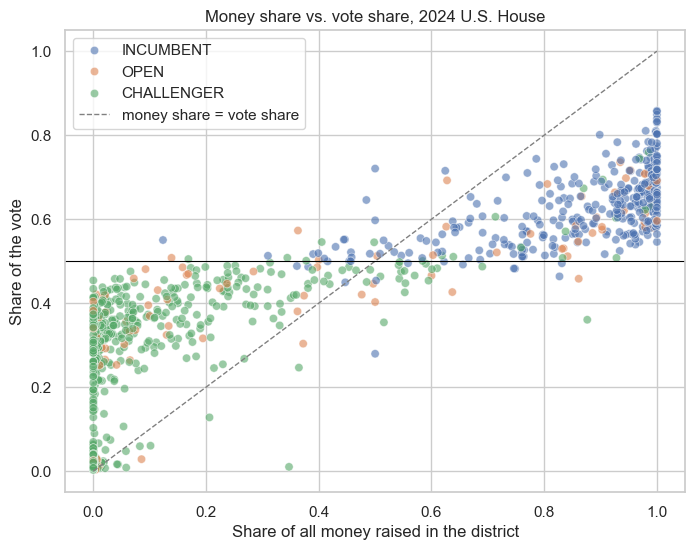

Correlation: 0.86


In [16]:
os.makedirs("../Figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=d, x="money_share", y="vote_share", hue="status",
                hue_order=["INCUMBENT", "OPEN", "CHALLENGER"], alpha=0.6, ax=ax)
ax.plot([0, 1], [0, 1], ls="--", c="gray", lw=1, label="money share = vote share")
ax.axhline(0.5, c="black", lw=0.8)
ax.set(xlabel="Share of all money raised in the district",
       ylabel="Share of the vote",
       title="Money share vs. vote share, 2024 U.S. House")
ax.legend()
plt.savefig("../Figures/money_vs_votes.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Correlation: {d['money_share'].corr(d['vote_share']):.2f}")

**Money share vs. vote share**
- Money and votes move together strongly (correlation 0.86), but not one-for-one
- Money is much more lopsided than votes:
  - Candidates with almost no money often still got 30–45% of the vote
  - Candidates with nearly all the money usually got 55–85%, not 100%
  - Most points sit above the dashed line on the left and below it on the right
  - Partisanship sets a floor and a ceiling that money doesn't break through
- The stack of points at 0% money splits into two groups:
  - Major-party challengers who still got 30–45% from party voters alone
  - Third-party candidates near 0%
  - Money can't tell these apart, but party can, which is why party is a feature in the model
- Incumbents (blue) cluster in the top right: they raise most of the money and win
  - This is where correlation isn't causation: donors give to candidates who already look likely to win, so money is partly a *result* of expected success, not only a cause

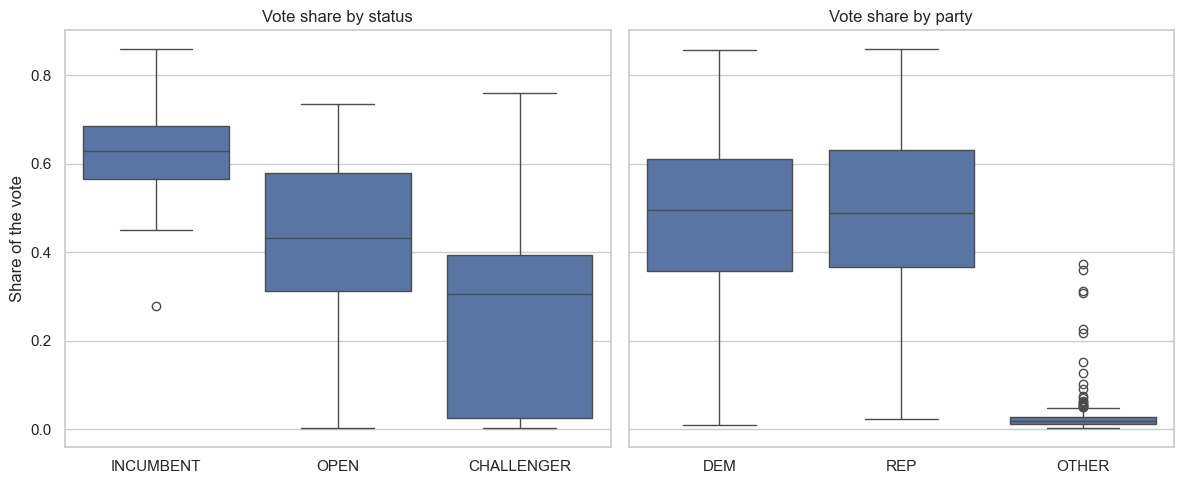

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
sns.boxplot(data=d, x="status", y="vote_share", order=["INCUMBENT", "OPEN", "CHALLENGER"], ax=axes[0])
axes[0].set(title="Vote share by status", xlabel="", ylabel="Share of the vote")
sns.boxplot(data=d, x="party_group", y="vote_share", order=["DEM", "REP", "OTHER"], ax=axes[1])
axes[1].set(title="Vote share by party", xlabel="")
plt.tight_layout()
plt.savefig("../Figures/vote_share_by_status_party.png", dpi=150, bbox_inches="tight")
plt.show()

**Vote share by status and party**
- Incumbency is a strong signal:
  - Incumbents had a median vote share of about 63%, and nearly all got over 45%
  - Open-seat candidates were spread widely (the middle half ranged from about 31% to 58%)
  - Challengers had a median of about 30%, with a long tail down to 0% (mostly third-party challengers)
- Democrats and Republicans look almost identical (median about 49% each)
  - So party alone doesn't say *which* major party wins
  - What it does is separate major-party candidates from third-party candidates, whose median vote share was only about 2%

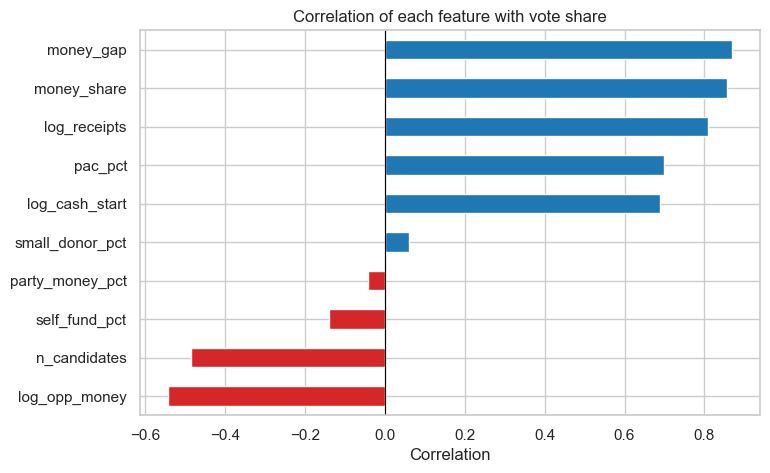

log_opp_money     -0.54
n_candidates      -0.49
self_fund_pct     -0.14
party_money_pct   -0.04
small_donor_pct    0.06
log_cash_start     0.69
pac_pct            0.70
log_receipts       0.81
money_share        0.86
money_gap          0.87
Name: vote_share, dtype: float64


In [18]:
corr = (d[feature_cols + [target]].select_dtypes("number")
        .corr()[target].drop(target).sort_values())

fig, ax = plt.subplots(figsize=(8, 5))
corr.plot.barh(ax=ax, color=np.where(corr > 0, "tab:blue", "tab:red"))
ax.axvline(0, c="black", lw=0.8)
ax.set(title="Correlation of each feature with vote share", xlabel="Correlation")
plt.savefig("../Figures/feature_correlations.png", dpi=150, bbox_inches="tight")
plt.show()
print(corr.round(2))

**Correlation of each feature with vote share**
- Strongest: the three money-in-the-race features
  - Money gap (0.87), money share (0.86) and total raised (0.81)
  - They measure related things, so they overlap; the permutation importance later shows them sharing credit about equally
- Also strong: PAC share (0.70) and starting cash (0.69)
  - These are partly stand-ins for incumbency: incumbents get about 40% of their money from PACs and start the cycle with about $350K, while the typical challenger gets almost no PAC money and starts with $0 (see the defaults table at the end of the notebook)
- Negative:
  - Opponents' money (−0.54): the more the other candidates raise, the lower your share
  - Number of candidates (−0.49): more candidates split the vote
  - Self-funding (−0.14): self-funders are often long-shot challengers
- Near zero:
  - Small-donor share (0.06) and party-committee share (−0.04)
  - Party-committee money is 0 for most candidates
  - These are kept so the models can test them, but they're unlikely to matter
- Note: this chart only includes numeric features. Status and party don't appear here, but the box plot shows they matter a lot

In [19]:
# Split by DISTRICT
groups = d["key"]

# 70% of districts for training, 30% held back
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss.split(d, groups=groups))

# split the held-back 30% in half - 15% validation, 15% test
temp = d.iloc[temp_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_pos, test_pos = next(gss2.split(temp, groups=temp["key"]))
val_idx, test_idx = temp_idx[val_pos], temp_idx[test_pos]

train, val, test = d.iloc[train_idx], d.iloc[val_idx], d.iloc[test_idx]

X_train, y_train = train[feature_cols], train[target]
X_val,   y_val   = val[feature_cols],   val[target]
X_test,  y_test  = test[feature_cols],  test[target]

# checks
print(f"{'set':<6}{'rows':>6}{'% rows':>8}{'districts':>11}{'mean vote share':>17}{'% incumbent':>13}")
for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:<6}{len(part):>6}{len(part)/len(d):>8.0%}{part['key'].nunique():>11}"
          f"{part[target].mean():>17.3f}{(part['status'] == 'INCUMBENT').mean():>13.0%}")

overlap = (set(train.key) & set(val.key)) | (set(train.key) & set(test.key)) | (set(val.key) & set(test.key))
print("\nDistricts in more than one set:", len(overlap))

set     rows  % rows  districts  mean vote share  % incumbent
train    705     69%        283            0.401          35%
val      163     16%         61            0.374          33%
test     155     15%         61            0.393          34%

Districts in more than one set: 0


In [20]:
cat_cols = ["state_po", "party_group", "status"]
num_cols = [c for c in feature_cols if c not in cat_cols]

prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),   # text -> 0/1 columns
    ("num", StandardScaler(), num_cols),                         # numbers -> same scale
])

def winner_accuracy(part, preds):
    tmp = pd.DataFrame({"key": part["key"].values, "actual": part[target].values, "pred": preds})
    actual_winner = tmp.groupby("key")["actual"].idxmax()
    predicted_winner = tmp.groupby("key")["pred"].idxmax()
    return (actual_winner == predicted_winner).mean()

def score(name, part, y_true, preds, train_mae=None):
    return {"model": name,
            "train MAE (pts)": None if train_mae is None else round(train_mae * 100, 1),
            "val MAE (pts)": round(mean_absolute_error(y_true, preds) * 100, 1),
            "val RMSE (pts)": round(root_mean_squared_error(y_true, preds) * 100, 1),
            "val R²": round(r2_score(y_true, preds), 3),
            "val winner acc": f"{winner_accuracy(part, preds):.0%}"}

results = []

# Baseline: predict the training average for everyone
baseline_pred = np.full(len(y_val), y_train.mean())
results.append(score("Baseline (average)", val, y_val, baseline_pred))

models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                           random_state=42, n_jobs=-1),
    "Gradient boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                                   max_depth=3, random_state=42),
}

fitted = {}
for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    train_mae = mean_absolute_error(y_train, pipe.predict(X_train))
    results.append(score(name, val, y_val, pipe.predict(X_val), train_mae))

results_df = pd.DataFrame(results)
results_df

,model,train MAE (pts),val MAE (pts),val RMSE (pts),val R²,val winner acc
0,Baseline (average),NaN,21.0,24.9,-0.012,93%
1,Linear regression,4.7,4.8,6.5,0.931,95%
2,Random forest,2.3,4.4,6.2,0.936,95%
3,Gradient boosting,2.5,4.4,6.1,0.939,95%


In [21]:
# The average baseline predicts the same value for everyone, so it can't pick a winner.
# Its "93%" came from row order (rows were sorted by money), i.e. it measured "top fundraiser wins".
results_df.loc[0, "val winner acc"] = "n/a (all ties)"

print(f"Top fundraiser won: {winner_accuracy(val, val['money_share'].values):.0%} of validation districts")
print(f"Top fundraiser won: {winner_accuracy(d, d['money_share'].values):.0%} of ALL {d['key'].nunique()} districts")
results_df

Top fundraiser won: 93% of validation districts
Top fundraiser won: 94% of ALL 405 districts


,model,train MAE (pts),val MAE (pts),val RMSE (pts),val R²,val winner acc
0,Baseline (average),NaN,21.0,24.9,-0.012,n/a (all ties)
1,Linear regression,4.7,4.8,6.5,0.931,95%
2,Random forest,2.3,4.4,6.2,0.936,95%
3,Gradient boosting,2.5,4.4,6.1,0.939,95%


In [22]:
dev = pd.concat([train, val])          # test set stays untouched
cv = GroupKFold(n_splits=5)            # 5 folds, each district in exactly one fold

cv_rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    s = cross_validate(pipe, dev[feature_cols], dev[target], groups=dev["key"], cv=cv,
                       scoring=["neg_mean_absolute_error", "r2"])
    mae = -s["test_neg_mean_absolute_error"] * 100
    cv_rows.append({"model": name,
                    "CV MAE (pts)": f"{mae.mean():.2f} ± {mae.std():.2f}",
                    "CV R²": f"{s['test_r2'].mean():.3f} ± {s['test_r2'].std():.3f}"})
pd.DataFrame(cv_rows)

,model,CV MAE (pts),CV R²
0,Linear regression,4.83 ± 0.48,0.925 ± 0.013
1,Random forest,4.08 ± 0.43,0.943 ± 0.013
2,Gradient boosting,4.19 ± 0.38,0.942 ± 0.011


### Model comparison (5-fold cross-validation, grouped by district)

**How to read the metrics**
- **MAE (mean absolute error), in percentage points:** the average gap between actual and predicted vote share
  - 4.08 means a typical prediction is about 4 points off (e.g., predicted 51%, actual 55%)
  - I use "points" instead of "%" because vote share is already a percentage: "4% off" could be misread as 4% *of* 51% (about 2 points), when the error is actually 4 percentage points
- **± value:** how much the score moved across the 5 folds, i.e. how uncertain it is
- **R²:** how much of the variation in vote share the model explains, compared with guessing the average for everyone
  - 0 = no better than the average, 1 = perfect

**Results**
- Random forest: MAE 4.08 ± 0.43 points, R² 0.943
- Gradient boosting: MAE 4.19 ± 0.38 points, R² 0.942
- Linear regression: MAE 4.83 ± 0.48 points, R² 0.925
- Random forest and gradient boosting are effectively tied: the difference between them is much smaller than the fold-to-fold variation
- Both clearly beat linear regression, which suggests the relationship between money and votes isn't a straight line (as the flattened shape of the money-share chart showed)
- **I chose random forest because it had the lowest cross-validated MAE**

**Why winner accuracy isn't used to compare models**
- The top fundraiser alone won 93% of validation districts (94% of all 405 districts)
- Every model picked 95% of validation winners, a difference of about one race
- The models' real value is predicting *how much* of the vote each candidate gets (about 4 points off on average, versus 21 points for guessing the average)

In [23]:
# Retrain the chosen model on train + validation
final_model = Pipeline([
    ("prep", prep),
    ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                    random_state=42, n_jobs=-1)),
])
final_model.fit(dev[feature_cols], dev[target])

# score once on the untouched test set
test_pred = final_model.predict(X_test)
print("FINAL TEST RESULTS (random forest, trained on train + validation)")
print(f"  MAE:  {mean_absolute_error(y_test, test_pred) * 100:.1f} percentage points")
print(f"  RMSE: {root_mean_squared_error(y_test, test_pred) * 100:.1f} percentage points")
print(f"  R²:   {r2_score(y_test, test_pred):.3f}")
print(f"  Winner accuracy: {winner_accuracy(test, test_pred):.0%} of {test['key'].nunique()} districts")
print(f"  (Top fundraiser won {winner_accuracy(test, test['money_share'].values):.0%} of test districts)")

# 3) save
os.makedirs("../Models", exist_ok=True)
joblib.dump(final_model, "../Models/vote_share_model.pkl")
print("\nSaved ../Models/vote_share_model.pkl")

FINAL TEST RESULTS (random forest, trained on train + validation)
  MAE:  3.8 percentage points
  RMSE: 6.1 percentage points
  R²:   0.932
  Winner accuracy: 93% of 61 districts
  (Top fundraiser won 90% of test districts)

Saved ../Models/vote_share_model.pkl


### Final test results
- The random forest was retrained on the training and validation sets combined, then scored once on the 15% test set
- No decisions were based on the test set, so these scores are an honest estimate of how the model does on new races

**Results**
- **MAE:** 3.8 percentage points
- **RMSE:** 6.1 percentage points
  - Like MAE, but big misses count more, so it's always higher
- **R²:** 0.932
- **Winner accuracy:** 93% of 61 districts
  - The top fundraiser alone won 90%, so the model called 2 more races correctly

**Does it generalize?**
- The test scores fall within the cross-validation range (MAE 4.08 ± 0.43, R² 0.943 ± 0.013)
- So the model performs on races it has never seen about as well as expected, instead of memorizing the training data

In [24]:
# test error by type of candidate and race
eval_df = test[["key", "candidate", "party_group", "status", target]].copy()
eval_df["pred"] = test_pred
eval_df["abs_err"] = (eval_df[target] - eval_df["pred"]).abs() * 100

# Close race = winner beat the runner-up by less than 10 points
margin = eval_df.groupby("key")[target].apply(lambda s: s.nlargest(2).iloc[0] - s.nlargest(2).iloc[-1])
close_keys = margin[margin < 0.10].index

breakdown = {
    "All candidates": eval_df,
    "Major-party (DEM/REP)": eval_df[eval_df["party_group"] != "OTHER"],
    "Third-party": eval_df[eval_df["party_group"] == "OTHER"],
    "Incumbents": eval_df[eval_df["status"] == "INCUMBENT"],
    "Open seats": eval_df[eval_df["status"] == "OPEN"],
    "Close races (<10-pt margin)": eval_df[eval_df["key"].isin(close_keys)],
}
rows = [{"group": g, "candidates": len(x), "MAE (pts)": round(x["abs_err"].mean(), 1)}
        for g, x in breakdown.items()]
print(pd.DataFrame(rows).to_string(index=False))

# Winner accuracy in close races only
close_mask = test["key"].isin(close_keys).values
print(f"\nClose races in the test set: {len(close_keys)} districts")
print(f"Winner accuracy in close races: {winner_accuracy(test[close_mask], test_pred[close_mask]):.0%}")

                      group  candidates  MAE (pts)
             All candidates         155        3.8
      Major-party (DEM/REP)         122        4.3
                Third-party          33        2.1
                 Incumbents          52        3.7
                 Open seats          24        4.4
Close races (<10-pt margin)          26        4.5

Close races in the test set: 9 districts
Winner accuracy in close races: 67%


### Where the model is strong and where it's weak

| Group | Candidates | MAE (pts) |
|---|---|---|
| All candidates | 155 | 3.8 |
| Major-party (DEM/REP) | 122 | 4.3 |
| Third-party | 33 | 2.1 |
| Incumbents | 52 | 3.7 |
| Open seats | 24 | 4.4 |
| Close races (<10-pt margin) | 26 | 4.5 |

**What the breakdown shows**
- The overall error of 3.8 points is pulled down by third-party candidates, who are easy to predict near 0%
- For major-party candidates, the error is higher: 4.3 points
- The error is highest for:
  - Open seats (4.4): there's no incumbent to anchor the prediction
  - Close races (4.5)

**Close races are the model's main limitation**
- In the 9 test districts decided by less than 10 points, the model picked the winner in 6 (67%)
- With an error of about 4.5 points per candidate, a race within a few points can easily flip
- The model is good at estimating *how much* of the vote a candidate gets, but campaign finance alone can't reliably call a competitive race
- Nine races is a small sample, so this number isn't precise

c:\Users\Janna Hoyne\Desktop\FInal_2\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Janna Hoyne\Desktop\FInal_2\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Janna Hoyne\Desktop\FInal_2\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Janna Hoyne\Desktop\FInal_2\venv\Lib\sit

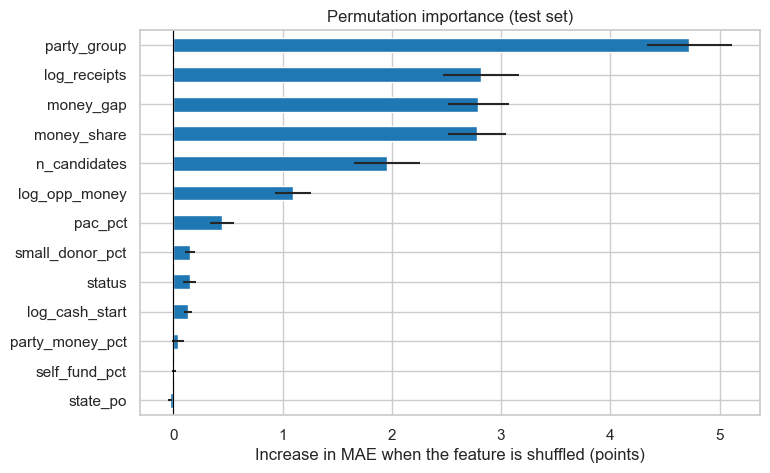

party_group        4.72
log_receipts       2.81
money_gap          2.79
money_share        2.78
n_candidates       1.96
log_opp_money      1.10
pac_pct            0.45
small_donor_pct    0.15
status             0.15
log_cash_start     0.13
party_money_pct    0.04
self_fund_pct      0.01
state_po          -0.03
dtype: float64


In [25]:
pi = permutation_importance(final_model, X_test, y_test, n_repeats=30, random_state=42,
                            scoring="neg_mean_absolute_error")

imp = pd.Series(pi.importances_mean * 100, index=feature_cols).sort_values()
err = pd.Series(pi.importances_std * 100, index=feature_cols)[imp.index]

fig, ax = plt.subplots(figsize=(8, 5))
imp.plot.barh(xerr=err, ax=ax, color="tab:blue")
ax.axvline(0, c="black", lw=0.8)
ax.set(title="Permutation importance (test set)",
       xlabel="Increase in MAE when the feature is shuffled (points)")
plt.savefig("../Figures/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print(imp.sort_values(ascending=False).round(2))

### What the model relied on (permutation importance)
- Permutation importance shuffles one feature at a time on the test set and measures how much the error goes up
- A bigger increase means the model relied on that feature more (the numbers are points of MAE added)

**Results**
- **Party (+4.72 points)** is the single most important feature
  - As the box plot showed, it doesn't distinguish Democrats from Republicans; it separates major-party candidates from third-party candidates
- **The three money-in-the-race features** each add about 2.8 points: total raised (2.81), money gap (2.79) and money share (2.78)
  - Their nearly identical scores are a sign they **share credit**: when one is shuffled, the model falls back on the other two
  - So money as a whole is more important than any single bar suggests
- **Number of candidates (+1.96)** matters because more candidates split the vote
- **Opponents' money (+1.10)** adds to the money picture: what the other candidates raised matters, not just your own total
- **Incumbency status scores only +0.15,** even though incumbents clearly win more (see the box plot)
  - This isn't a contradiction: incumbents raise the most money, get the most PAC money and start the cycle with cash, so the money features already carry the incumbency information
  - Shuffling status alone removes little
- **State, self-funding and party-committee money add essentially nothing** (−0.03 to 0.04)
  - With 50 states and only a few districts each, there isn't enough data to learn state-level patterns

**Limitation**
- This shows what the model *uses*, not what *causes* votes
- Money and votes are linked in both directions: donors give to candidates who already look likely to win

In [26]:
# if someone leaves one blank, the app uses the typical value
# for a candidate with the same party and status
optional_cols = ["small_donor_pct", "pac_pct", "party_money_pct", "self_fund_pct", "log_cash_start"]

medians = d.groupby(["party_group", "status"])[optional_cols].median()
counts = d.groupby(["party_group", "status"]).size().rename("candidates")
print(pd.concat([counts, medians.round(3)], axis=1))

defaults = {
    "features": feature_cols,                                       # the order the model expects
    "states": sorted(d["state_po"].unique().tolist()),              # dropdown
    "party_groups": ["DEM", "REP", "OTHER"],
    "statuses": ["INCUMBENT", "CHALLENGER", "OPEN"],
    "by_group": {f"{p}|{s}": row.round(4).to_dict() for (p, s), row in medians.iterrows()},
    "overall": d[optional_cols].median().round(4).to_dict(),        # fallback for rare combos
}

with open("../Models/defaults.json", "w") as f:
    json.dump(defaults, f, indent=2)
print("\nSaved ../Models/defaults.json")

                        candidates  small_donor_pct  pac_pct  party_money_pct  \
party_group status                                                              
DEM         CHALLENGER         190            0.237    0.027              0.0   
            INCUMBENT          174            0.054    0.412              0.0   
            OPEN                44            0.132    0.042              0.0   
OTHER       CHALLENGER         192            0.000    0.000              0.0   
            OPEN                18            0.000    0.000              0.0   
REP         CHALLENGER         185            0.078    0.001              0.0   
            INCUMBENT          178            0.053    0.380              0.0   
            OPEN                42            0.055    0.142              0.0   

                        self_fund_pct  log_cash_start  
party_group status                                     
DEM         CHALLENGER          0.000           0.000  
            INCUMBENT

### Version 2: same-party candidates

**What I found while testing the app**
- The model mispredicted Alaska's at-large race (AK-0)
- It gave Eric Hafner, a second Democrat who raised $0, 21% of the vote; he actually got 1%
- The model had learned that a major-party candidate with no money still gets a large share from party voters
  - That's true when they're *the* party's candidate
  - It isn't true when a stronger candidate from the same party is also on the ballot

**Where this happens**
- States with top-two or top-four primaries (California, Washington, Alaska) and Louisiana
- In this data: 32 candidates in 12 races

**The fix I tested: two new features**
- **same_party_rivals:** how many other candidates in the race share this candidate's major party
- **top_in_party:** whether the candidate raised the most money among their party's candidates in the race

**How I decided**
- Version 2 is chosen or rejected using cross-validation only, so the test set isn't used to make the decision

In [27]:
# features
major = d["party_group"].isin(["DEM", "REP"])

# Other candidates in the race from the same major party (0 for third-party candidates)
d["same_party_rivals"] = np.where(
    major, d.groupby(["key", "party_group"])["candidate"].transform("count") - 1, 0)

# 1 if this candidate raised the most among their party's candidates in the race
rank_in_party = d.groupby(["key", "party_group"])["log_receipts"].rank(method="first", ascending=False)
d["top_in_party"] = np.where(major, (rank_in_party == 1).astype(int), 1)

print("Candidates with a same-party rival:", (d["same_party_rivals"] > 0).sum())
print("Races with same-party rivals:", d.loc[d["same_party_rivals"] > 0, "key"].nunique())
print(d.loc[d["same_party_rivals"] > 0, ["key", "candidate", "party_group", "log_receipts",
                                         "top_in_party", "vote_share"]].head(12).to_string())

# Same split with the new columns
feature_cols_v2 = feature_cols + ["same_party_rivals", "top_in_party"]
train, val, test = d.iloc[train_idx], d.iloc[val_idx], d.iloc[test_idx]
dev = pd.concat([train, val])

num_cols_v2 = [c for c in feature_cols_v2 if c not in cat_cols]
prep_v2 = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols_v2),
])

# Cross-validation: v1 vs v2, same folds
cv_rows = []
for version, feats, pre in [("v1", feature_cols, prep), ("v2", feature_cols_v2, prep_v2)]:
    for name in ["Random forest", "Gradient boosting"]:
        pipe = Pipeline([("prep", pre), ("model", models[name])])
        s = cross_validate(pipe, dev[feats], dev[target], groups=dev["key"], cv=cv,
                           scoring=["neg_mean_absolute_error", "r2"])
        mae = -s["test_neg_mean_absolute_error"] * 100
        cv_rows.append({"version": version, "model": name,
                        "CV MAE (pts)": f"{mae.mean():.2f} ± {mae.std():.2f}",
                        "CV R²": f"{s['test_r2'].mean():.3f} ± {s['test_r2'].std():.3f}"})
pd.DataFrame(cv_rows)

Candidates with a same-party rival: 32
Races with same-party rivals: 12
       key             candidate party_group  log_receipts  top_in_party  vote_share
1     LA-4          MIKE JOHNSON         REP      7.298134             1    0.858197
6     LA-1         STEVE SCALISE         REP      7.168269             1    0.667679
7     AK-0  MARY SATTLER PELTOLA         DEM      7.128514             1    0.463740
69   CA-16          SAM LICCARDO         DEM      6.794240             1    0.582162
145  CA-16              EVAN LOW         DEM      6.570294             0    0.417838
213   WA-4          DAN NEWHOUSE         REP      6.400148             1    0.520169
240  CA-20            VINCE FONG         REP      6.363967             1    0.650519
252  CA-34           JIMMY GOMEZ         DEM      6.351343             1    0.556421
253  CA-12        LATEEFAH SIMON         DEM      6.348589             1    0.654274
272   LA-2        TROY A. CARTER         DEM      6.310098             1    0.

,version,model,CV MAE (pts),CV R²
0,v1,Random forest,4.08 ± 0.43,0.943 ± 0.013
1,v1,Gradient boosting,4.19 ± 0.38,0.942 ± 0.011
2,v2,Random forest,4.05 ± 0.43,0.944 ± 0.013
3,v2,Gradient boosting,4.15 ± 0.39,0.943 ± 0.011


In [28]:
# each candidate is predicted by a model that never saw their district
rf_v1 = Pipeline([("prep", prep),    ("model", models["Random forest"])])
rf_v2 = Pipeline([("prep", prep_v2), ("model", models["Random forest"])])
oof_v1 = cross_val_predict(rf_v1, dev[feature_cols],    dev[target], groups=dev["key"], cv=cv)
oof_v2 = cross_val_predict(rf_v2, dev[feature_cols_v2], dev[target], groups=dev["key"], cv=cv)

err_v1 = (dev[target] - oof_v1).abs() * 100
err_v2 = (dev[target] - oof_v2).abs() * 100
rivals = (dev["same_party_rivals"] > 0).values

summary = pd.DataFrame({
    "candidates": [len(dev), rivals.sum(), (~rivals).sum()],
    "v1 MAE (pts)": [err_v1.mean(), err_v1[rivals].mean(), err_v1[~rivals].mean()],
    "v2 MAE (pts)": [err_v2.mean(), err_v2[rivals].mean(), err_v2[~rivals].mean()],
}, index=["All (train + val)", "Has a same-party rival", "No same-party rival"]).round(1)
print(summary)

# The individual same-party candidates
detail = dev.loc[rivals, ["key", "candidate", "party_group", "top_in_party", target]].copy()
detail["v1 pred"] = oof_v1[rivals]
detail["v2 pred"] = oof_v2[rivals]
print(detail.sort_values("key").round(3).to_string())

                        candidates  v1 MAE (pts)  v2 MAE (pts)
All (train + val)              868           4.1           4.0
Has a same-party rival          28           5.9           5.7
No same-party rival            840           4.0           4.0
       key                 candidate party_group  top_in_party  vote_share  v1 pred  v2 pred
253  CA-12            LATEEFAH SIMON         DEM             1       0.654    0.599    0.598
539  CA-12             JENNIFER TRAN         DEM             0       0.346    0.367    0.316
69   CA-16              SAM LICCARDO         DEM             1       0.582    0.482    0.482
145  CA-16                  EVAN LOW         DEM             0       0.418    0.470    0.470
520  CA-20            MIKE BOUDREAUX         REP             0       0.349    0.418    0.411
240  CA-20                VINCE FONG         REP             1       0.651    0.599    0.600
252  CA-34               JIMMY GOMEZ         DEM             1       0.556    0.607    0.607
507 

**Result: Version 2 is not adopted**
- Cross-validated MAE barely changed overall: 4.08 → 4.05, well within the ±0.43 fold-to-fold variation
- On the 28 candidates with a same-party rival (in the training and validation sets), it improved only from 5.9 to 5.7 points

**Why it didn't work: same-party races come in two opposite kinds**
- **Top-two states (California, Washington):** both finalists are often from the same party
  - The weaker one still gets about 35–46% because they're the only alternative for the other party's voters
  - Example: Evan Low, CA-16, 42%
- **Open primaries with candidates from both parties (Louisiana, Alaska):** the weaker same-party candidate gets very little
  - Example: Peter Williams, LA-6, 2%
- So "not the top fundraiser in their party" means opposite things in the two cases, and with only 12 such races, the model can't learn both

**What I did instead**
- Kept the original model (Version 1); its test results above remain the reported results
- The app flags races with multiple candidates from the same party as less reliable
- With more election years, a feature for the primary system (top-two, open primary or partisan primary) could address this properly

Janna Hoyne ANA 680